# **SDD Spatial Resolution Fit  |  Crab 2-50 keV**

In [8]:
from pathlib import Path
from typing import Any, NamedTuple, Optional

import numpy as np
from numpy.typing import NDArray
import matplotlib as mpl
import matplotlib.pyplot as plt
from astropy.io.fits import FITS_rec

from bloodmoon.io import simulation_files
from bloodmoon.mask import CodedMaskCamera, codedmask
from bloodmoon.mask import count
from bloodmoon.types import CoordEquatorial
import darksun as ds
from darksun.benchmarking import source_catalogue_data
from darksun.data import DataLoader, CatalogueLoader

plt.rcdefaults()

RCPARAMS = {
    'axes.formatter.limits': (-3, 3),
    'savefig.bbox': 'tight',
}
mpl.rcParams.update(RCPARAMS)

ds.show.set_figures_darkbkg()

In [9]:
def check_and_pick(parent: Path, pattern: str) -> Path:
    matches = tuple(parent.glob(pattern))
    if not matches:
        raise ValueError(f"A file matching the pattern {str(parent / pattern)} is expected but missing.")
    f, *extra_matches = matches
    if extra_matches:
        raise ValueError(
            f"Found unexpected extra matches for glob pattern {str(parent / pattern)}."
            f"File with pattern {pattern} should be unique"
        )
    return f

class CountListsMap(NamedTuple):
    common: NDArray
    unique: NDArray
    idx_a: NDArray
    idx_b: NDArray

def get_ctsmap_for_lists(
    phlist_A: FITS_rec,
    phlist_B: FITS_rec,
    select_by: str = 'ID',
    uniqueIDs: bool = True,
) -> CountListsMap:
    """
    Finds common count IDs in given photon lists.
    Returns the sorted, unique src IDs that are in both input lists, and the index map.
    """
    ida, idb = phlist_A[select_by], phlist_B[select_by]
    common, idx_a, idx_b = np.intersect1d(ida, idb, assume_unique=uniqueIDs, return_indices=True)
    unique = np.setxor1d(ida, idb, assume_unique=uniqueIDs)
    return CountListsMap(common, unique, idx_a, idx_b)

def get_source_coords(sourceID: str, catalogue: CatalogueLoader) -> CoordEquatorial:
    """Extracts the source RA/Dec coords from catalogue."""
    data = source_catalogue_data(sourceID, catalogue.DLdata)
    return CoordEquatorial(data['RA'], data['DEC'])

def select_target_srcs(
    photons: FITS_rec,
    srcIDs: str | tuple[str, ...],
    catalogue: CatalogueLoader,
) -> FITS_rec:
    """Filters the input photon list for the given sources equatorial coords."""
    srcIDs_ = (srcIDs,) if isinstance(srcIDs, str) else srcIDs
    coords = tuple(get_source_coords(src, catalogue) for src in srcIDs_)
    phs = ds.select_source_photons(coords, photons, False)
    return phs

In [10]:
MASK_FITS: str = "mask_NTHT_20260129_CORRECTED.fits"
SKYFIELD: str = "IROSDummy"
DATA_FITS: str = "Crab_grid_thin_mask_infdense_sdd_5ks_2-50keV"

ID_CAMERA: str = "cam1a"

E_min: float = 2.0  # [keV]
E_max: float = 50.0  # [keV]

UPS_X, UPS_Y = 5, 2
hide_bulk_els_y: float = 1.5   # [mm]

In [11]:
BASEDIR: str = "/mnt/dbb8f47e-da06-47bf-8ef5-038092af70f7/Edos_Magnificent_Manor/PhD_AASS/Coding/IROS_Data/Simulations"
# BASEDIR: str = "/mnt/d/PhD_AASS/Coding/Images_fits"

DATAPATH: str = Path(f"{BASEDIR}/{SKYFIELD}/{DATA_FITS}")

In [12]:
wfm: CodedMaskCamera = codedmask(f'{BASEDIR}/{MASK_FITS}', UPS_X, UPS_Y, hide_bulk_els_y=hide_bulk_els_y)

cat = ds.get_catalogue(check_and_pick(DATAPATH, f'{ID_CAMERA}/*sources*.fits'))
sdl_detect, sdl_recons = map(
    lambda dataset: ds.get_data(check_and_pick(DATAPATH, f'{ID_CAMERA}/*{dataset}*.fits'), E_min=E_min, E_max=E_max),
    ('detected', 'reconstructed'),
)

In [13]:
SRC_ID: str = 's8'

phs_detect, phs_recons = map(lambda sdl: np.sort(select_target_srcs(sdl.DLdata, SRC_ID, cat)), (sdl_detect, sdl_recons))
sdd_detect, sdd_recons = map(lambda data: count(wfm, data)[0], (phs_detect, phs_recons))

CATALOG ='camera_benchmark_catalogue.fits' / Catalog file                        [astropy.io.fits.card]


UserInfo: using bulk mask of [0.0 x 1.5] mm.


In [14]:
len_detec, len_recons = map(len, (phs_detect, phs_recons))
len_unq_detec, len_unq_recons = map(lambda x: len(np.unique(x)), (phs_detect['ID'], phs_recons['ID']))

print(
    f'Selected source: {SRC_ID} in ({E_min}, {E_max}) keV\n\n'

    f'  * counts from detected list: {len_detec}\n'
    f'  * counts from reconstructed list: {len_recons}\n'
    f'  * delta counts: {len_detec - len_recons} ({(len_detec - len_recons) * 100 / len_detec:.4f} %)\n\n'

    f'  * repetitions in detected list: {len_detec - len_unq_detec} ({(len_detec - len_unq_detec) / len_detec} %)\n'
    f'  * repetitions in reconstructed list: {len_recons - len_unq_recons} ({(len_recons - len_unq_recons) / len_recons} %)'
)

Selected source: s8 in (2.0, 50.0) keV

  * counts from detected list: 1042121
  * counts from reconstructed list: 1030901
  * delta counts: 11220 (1.0767 %)

  * repetitions in detected list: 0 (0.0 %)
  * repetitions in reconstructed list: 1 (9.70025249757251e-07 %)


In [15]:
# remove repeted entries in reconstructed list

def remove_rpts(rec: FITS_rec, selectby: str = 'ID') -> FITS_rec:
    """Removes repeated entries in given record."""
    unq, idxs = np.unique(rec[selectby], return_index=True)
    len_rec, len_unq = map(len, (rec, unq))
    rec_ = rec[idxs] if (len_rec - len_unq > 0) else rec
    return rec_


phs_detect, phs_recons = map(remove_rpts, (phs_detect, phs_recons))

## **Visual Inspection**

In [16]:
AXIS: str = 'Y'

ctsmap = get_ctsmap_for_lists(phs_detect, phs_recons)
y_det, y_rec = phs_detect[AXIS][ctsmap.idx_a], phs_recons[AXIS][ctsmap.idx_b]

axflag = AXIS == 'Y'
mask_eldim = wfm.specs.mask_deltay if axflag else wfm.specs.mask_deltax
mask_pitch = wfm.specs.slit_deltay if axflag else wfm.specs.slit_deltax
bins = wfm.bins_detector.y if axflag else wfm.bins_detector.x

print(f'Analysing {'coarse' if axflag else 'fine'} axis...')

Analysing coarse axis...


In [17]:
def get_artefact_mask(camera: CodedMaskCamera, x: NDArray, bins: NDArray, axis: int = -1, hsdd: bool = False) -> NDArray:
    idxs = (bins[:-1] + bins[1:]) / 2
    if not hsdd:
        idxs = idxs * (camera.bulk.sum(axis=axis) > 0)
    symm_mask = (idxs > 0)
    btm, top = idxs[symm_mask][0] - mask_eldim / 2, idxs[symm_mask][-1] + mask_eldim / 2
    artfct_mask = ((-top <= x) & (x <= -btm)) | ((btm <= x) & (x <= top))
    return artfct_mask

In [18]:
artfct_mask = get_artefact_mask(wfm, y_det, bins, int(axflag))

y_det_flt, y_rec_flt = y_det[artfct_mask], y_rec[artfct_mask]

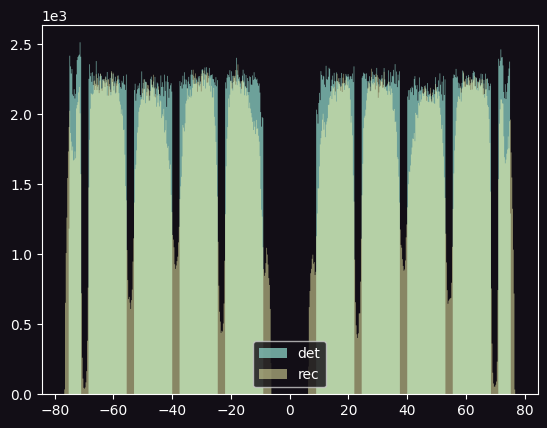

In [19]:
a, *_ = np.histogram(y_det_flt, bins)
b, *_ = np.histogram(y_rec_flt, bins)

_ = plt.stairs(a, bins, label='det', alpha=0.75, fill=True)  # a * artfct_mask
_ = plt.stairs(b, bins, label='rec', alpha=0.5, fill=True)   # b * artfct_mask
_ = plt.legend()

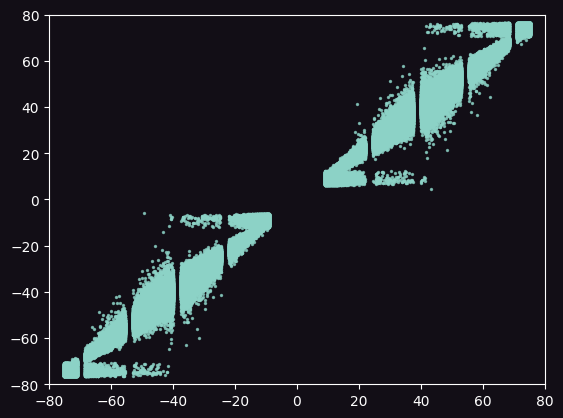

In [20]:
_ = plt.scatter(y_det_flt, y_rec_flt, alpha=0.75, s=2)
_ = plt.ylim((-80, 80))
_ = plt.xlim((-80, 80))

In [23]:
np.count_nonzero(phs_recons['SUBID'])

42

925802
60946
ENERGY (1 sigma): 4.3616 +/- 6.0384
EPHOTON (1 sigma): 4.3636 +/- 6.0297
RA (1 sigma): 266.4000 +/- 0.0000
DEC (1 sigma): -28.9400 +/- 0.0000
GRADE (1 sigma): 2.0000 +/- 0.0000


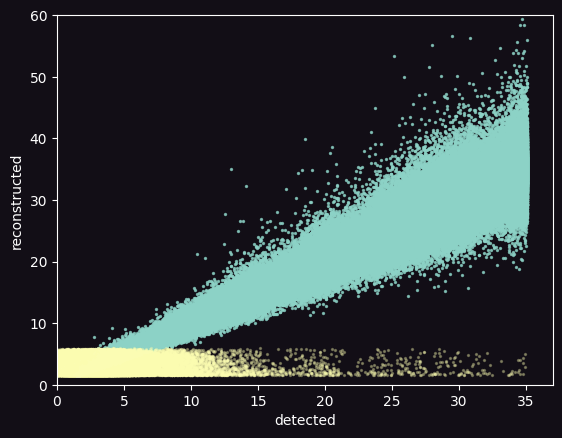

In [ ]:
mask = (phs_recons['Y_HSDD'] > 1.5) & (phs_recons['GRADE'] != 2)
y_det_hsdd, y_rec_hsdd = phs_recons['YPHOTON'][mask], phs_recons['Y_HSDD'][mask]

_ = plt.scatter(y_det_hsdd, y_rec_hsdd, alpha=0.75, s=2, label='GRADE != 2')
_ = plt.xlim((-1e-3, 37))
_ = plt.ylim((-1e-3, 60))
_ = plt.title('Detect Pos VS Reconstr Pos')
_ = plt.xlabel('detected [mm]')
_ = plt.ylabel('reconstructed [mm]')

print(len(y_det_hsdd))

# mask = (phs_recons['Y_HSDD'] > 1.5) & (phs_recons['Y_HSDD'] < 6) & ((phs_recons['YPHOTON'] > 8))
mask = (phs_recons['Y_HSDD'] > 1.5) & (phs_recons['GRADE'] == 2) & ((phs_recons['YPHOTON'] > 8))
y_det_hsdd, y_rec_hsdd = phs_recons['YPHOTON'][mask], phs_recons['Y_HSDD'][mask]

print(len(y_det_hsdd))

_ = plt.scatter(y_det_hsdd, y_rec_hsdd, alpha=0.75, s=2, label='GRADE == 2')
# _ = plt.legend()

mask = (phs_recons['GRADE'] == 1)
y_det_hsdd, y_rec_hsdd = phs_recons['YPHOTON'][mask], phs_recons['Y_HSDD'][mask]

print(len(y_det_hsdd))

_ = plt.scatter(y_det_hsdd, y_rec_hsdd, alpha=0.75, s=2, label='GRADE == 1')
_ = plt.legend()


ns = 1
flags = (
    'energy', 'ephoton', 'grade', 'success', 'goodness'
)
for flag in flags:
    f = flag.upper()
    print(f'{f} ({ns} sigma): {np.mean(phs_recons[f][mask]):.4f} +/- {ns * np.std(phs_recons[f][mask]):.4f}')